### Image Classification

In [29]:
# fmnist dataset image classicication using CNN architecture

# import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [30]:
# check the tensorflow version
print(tf.__version__)

2.21.0


In [31]:
# Load the fmnist dataset 

fasion_mnist = tf.keras.datasets.fashion_mnist.load_data()

# Seperate the training images from the test images and labels
(train_images, train_labels), (test_images, test_labels) = fasion_mnist

In [32]:
# shape of each dataset
print(train_images.shape)
print(train_labels.shape)
print(test_images.shape)
print(test_labels.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [33]:
train_labels

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

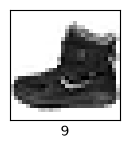

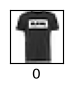

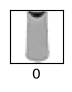

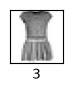

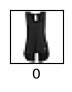

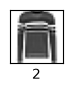

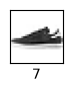

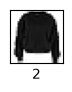

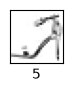

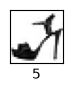

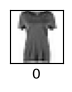

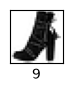

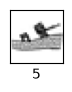

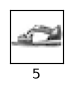

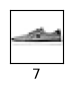

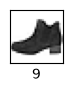

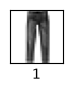

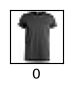

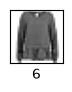

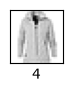

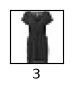

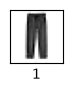

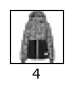

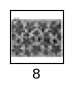

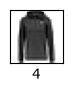

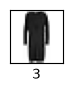

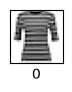

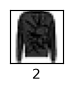

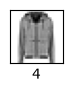

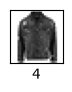

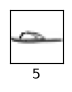

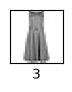

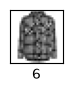

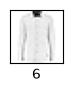

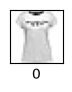

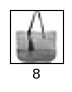

In [34]:
# Display some sample images
plt.figure(figsize=(10, 10))
for i in range (36):
    plt.subplot(6, 6, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap= plt.cm.binary)
    plt.xlabel(train_labels[i])
    plt.show()

In [35]:
len(train_images)

60000

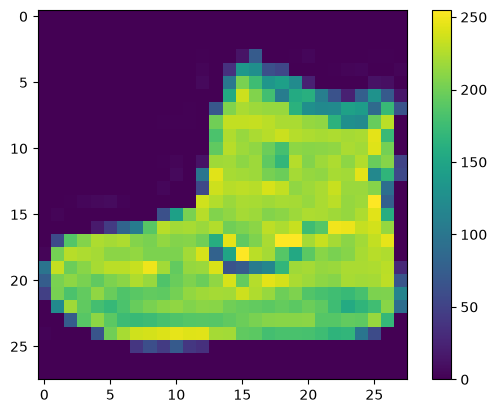

In [36]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [37]:
# Display the values of each picel in the image
print("pixel values:")
for row in train_images[0]:
    for pixel in row:
        print("{:3}".format(pixel), end= " ")
    print()

pixel values:
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0   0   1   4   0   0   0   0   1   1   0 
  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62  54   0   0   0   1   3   4   0   0   3 
  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134 144 123  23   0   0   0   0  12  10   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178 107 156 161 109  64  23  77 130  72  15 
  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216 216 163 127 121 122 146 141  88 172  66 
  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 232 233 229 223 223 21

In [38]:
# normalize the data
train_images = train_images/255
test_images = test_images/255

In [39]:
# convert images into float
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

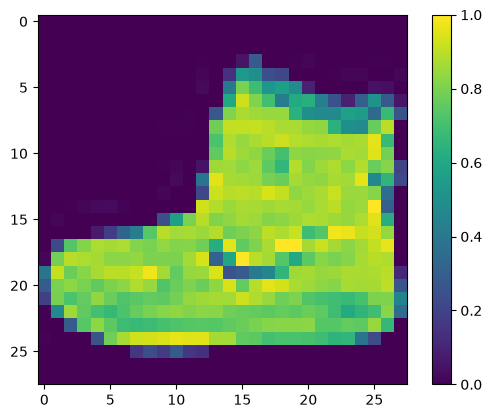

In [40]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

pixel values:
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0039 0.0 0.0 0.051 0.29 0.0 0.0 0.0039 0.016 0.0 0.0 0.0 0.0 0.0039 0.0039 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.012 0.0 0.14 0.53 0.5 0.24 0.21 0.0 0.0 0.0 0.0039 0.012 0.016 0.0 0.0 0.012 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.024 0.0 0.4 0.8 0.69 0.53 0.56 0.48 0.09 0.0 0.0 0.0 0.0 0.047 0.039 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.61 0.93 0.81 0.7 0.42 0.61 0.63 0.43 0.25 0.09 0.3 0.51 0.28 0.059 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0039 0.0 0.27 0.81 0.87 0.85 0.85 0.85 0.64 0.5 0.47 0.48 0.57 0.55 0.35 0.67 0.26 
0.0 0.0 0

<Figure size 640x480 with 0 Axes>

<Axes: >

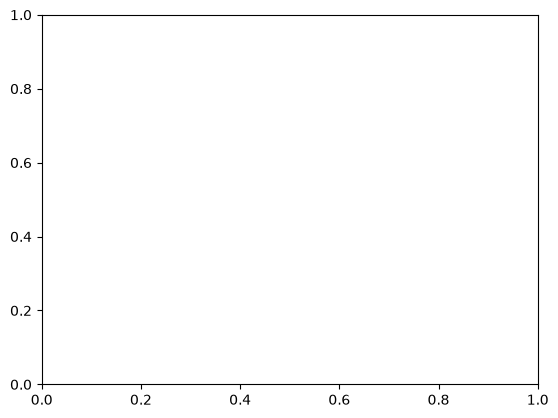

In [41]:
# Display the values of each pixel in the image
print("pixel values:")
for row in train_images[0]:
    for pixel in row:
        print("{:0.2}".format(pixel), end= " ")
    print()

# Display the complete output of the cell
display(plt.gcf())
display(plt.gca())

In [42]:
# Reshape the dimensions
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1)
test_images= test_images.reshape(test_images.shape[0], 28, 28, 1)

In [43]:
# Build the model

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),    #input layer

    # convolution block
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation= 'relu'),   #convolutional layer
    tf.keras.layers.MaxPool2D(pool_size=(3, 3)),   #pooling layer

    tf.keras.layers.Conv2D(filters = 64, kernel_size= (3,3)),   #convolutional layer
    tf.keras.layers.MaxPooling2D(),   #pooling layer

    # classification layers
    tf.keras.layers.Flatten(),   #flatten layer
    tf.keras.layers.Dense(28, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation= 'softmax')   #output layer
])

# compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 6, 6, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 28)             │        16,156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 28)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,262 (137.74 KB)

 Trainable params: 35,262 (137.74 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# train the mdoel
model.fit(train_images, train_labels, epochs=20, batch_size=16, validation_split=0.2)

Epoch 1/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 31s 10ms/step - accuracy: 0.8904 - loss: 0.2983 - val_accuracy: 0.9038 - val_loss: 0.2752
Epoch 2/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 34s 11ms/step - accuracy: 0.8970 - loss: 0.2838 - val_accuracy: 0.8975 - val_loss: 0.2808
Epoch 3/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 33s 11ms/step - accuracy: 0.8995 - loss: 0.2743 - val_accuracy: 0.8827 - val_loss: 0.3039
Epoch 4/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 33s 11ms/step - accuracy: 0.9008 - loss: 0.2694 - val_accuracy: 0.8952 - val_loss: 0.2860
Epoch 5/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 33s 11ms/step - accuracy: 0.9033 - loss: 0.2604 - val_accuracy: 0.8957 - val_loss: 0.2932
Epoch 6/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 32s 11ms/step - accuracy: 0.9064 - loss: 0.2530 - val_accuracy: 0.8957 - val_loss: 0.2912
Epoch 7/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 32s 11ms/step - accuracy: 0.9086 - loss: 0.2463 - val_accuracy: 0.9009 - val_loss: 0.2865
Epoch 8/20
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 32s 11ms/step - accuracy: 0.9094 -

In [56]:
# model evaluation
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('\nTest loss:', test_loss)
print('\nTest accuracy:', test_acc)

313/313 - 1s - 3ms/step - accuracy: 0.8978 - loss: 0.3359

Test loss: 0.3358820676803589

Test accuracy: 0.8978000283241272


In [57]:
# save the model
model.save('models_saved/fashion_mnist_model.h5')

### Make predictions

In [58]:
test_images.shape

(10000, 28, 28, 1)

In [59]:
predictions = model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [60]:
predictions[0]

array([1.3113770e-24, 1.5266199e-30, 4.0877664e-24, 4.2309800e-32,
       9.0959126e-26, 1.5428817e-06, 6.5240251e-28, 1.0913695e-07,
       5.0121370e-19, 9.9999833e-01], dtype=float32)

In [61]:
np.argmax(predictions[50])

np.int64(4)

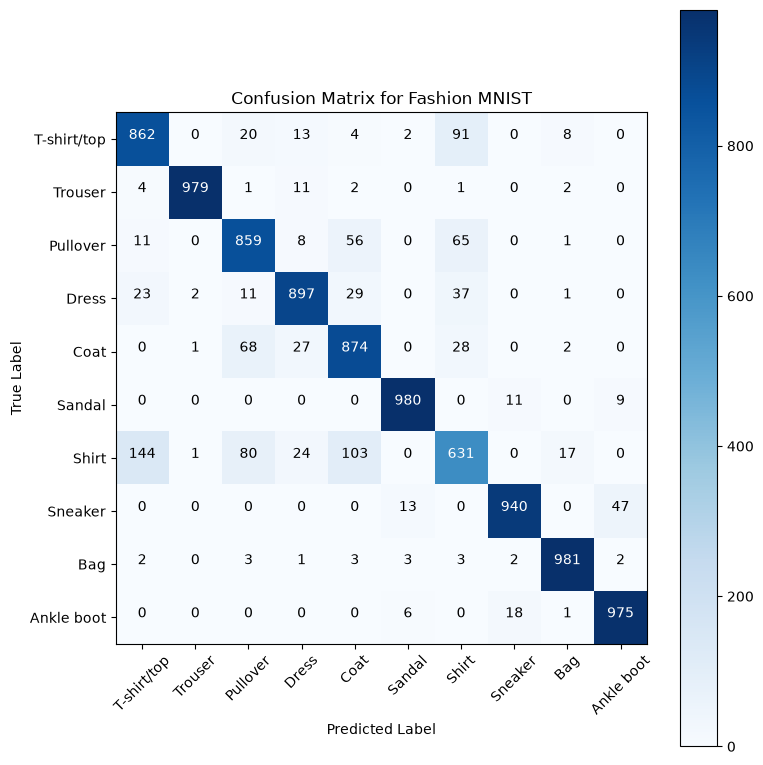

In [62]:
# Draw a confusion matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Convert continuous predictions to discrete class labels
predicted_labels = np.argmax(predictions, axis=1)

# Create the confusion matrix
cm = confusion_matrix(test_labels, predicted_labels)

# Define the class labels for Fashion MNIST
class_labels = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Plot the confusion matrix
plt.figure(figsize=(8, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Fashion MNIST')
plt.colorbar()

tick_marks = np.arange(len(class_labels))
plt.xticks(tick_marks, class_labels, rotation=45)
plt.yticks(tick_marks, class_labels)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Add values to the confusion matrix
for i in range(len(class_labels)):
    for j in range(len(class_labels)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.show()